# 04 — Variables causales
Rapport : `reports/04_features_report.md`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from src.config import load_config
cfg = load_config()
R = ROOT / "reports"; FIG = R / "figures"
def load(name): return json.loads((R / name).read_text())
def fig(name): display(Image(filename=str(FIG / name)))

In [2]:
from src.features.engineering import FEATURE_GROUPS, ALL_FEATURES, build_features
for g, f in FEATURE_GROUPS.items(): print(f'{g:<9} ({len(f)}):', f)

lags      (5): ['lag_1', 'lag_24', 'lag_48', 'lag_168', 'lag_336']
rolling   (6): ['roll_mean_24', 'roll_std_24', 'roll_mean_168', 'same_hour_mean_7d', 'profile_4w_median', 'frac_filled_168']
calendar  (9): ['hour', 'dayofweek', 'is_weekend', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'doy_sin', 'doy_cos']
holidays  (6): ['is_holiday', 'is_day_before_holiday', 'is_day_after_holiday', 'lag_24_was_holiday', 'lag_168_was_holiday', 'is_dec24_or_dec31']


## Démonstration de causalité : on modifie tout le jour J, ses variables ne changent pas

In [3]:
from src.data.preprocessing import load_processed
data = load_processed(cfg['data']['processed_dir']).asfreq('h').loc[:'2010-03-01']
D = pd.Timestamp('2010-02-10'); X1 = build_features(data)[ALL_FEATURES]
d2 = data.copy(); m = d2.index >= D
d2.loc[m, ['energy_kwh', 'energy_filled']] = d2.loc[m, ['energy_kwh', 'energy_filled']] * 7 + 3
X2 = build_features(d2)[ALL_FEATURES]; day = (X1.index >= D) & (X1.index < D + pd.Timedelta('1D'))
print('variables du jour J identiques :', X1[day].equals(X2[day]))

variables du jour J identiques : True


## Analyse sur le train

,Spearman avec y
same_hour_mean_7d,0.621
profile_4w_median,0.576
lag_24,0.517
lag_168,0.509
lag_48,0.471
lag_336,0.461
hour,0.345
roll_mean_168,0.344
roll_mean_24,0.327
doy_cos,0.279


,n_days,mean_kwh,std_kwh
"jours ouvrés (lun-ven, non fériés)",730.0,24.38,8.73
samedis,145.0,30.31,12.37
dimanches,147.0,29.86,12.51
jours fériés,30.0,25.78,10.63
veilles de férié,29.0,25.80,11.44
24/12 et 31/12,5.0,37.34,13.42


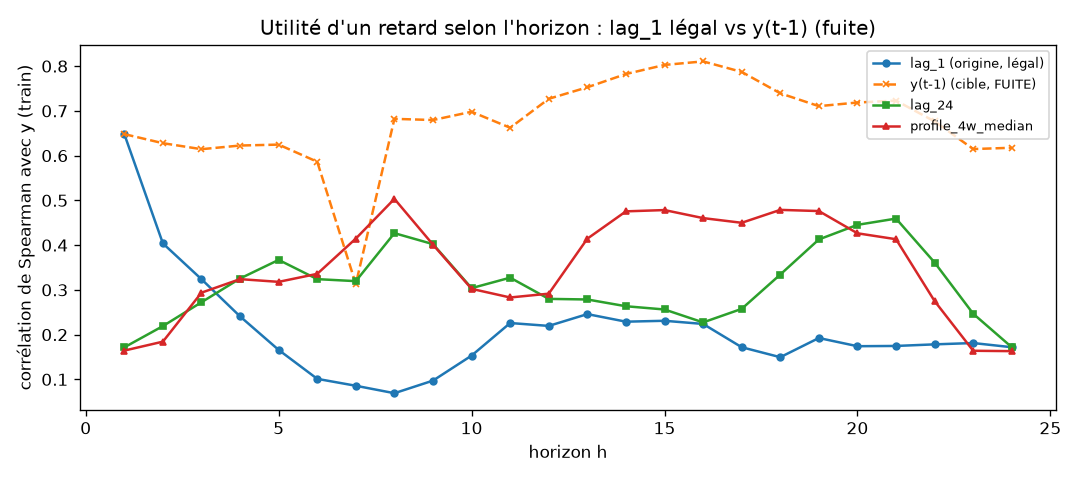

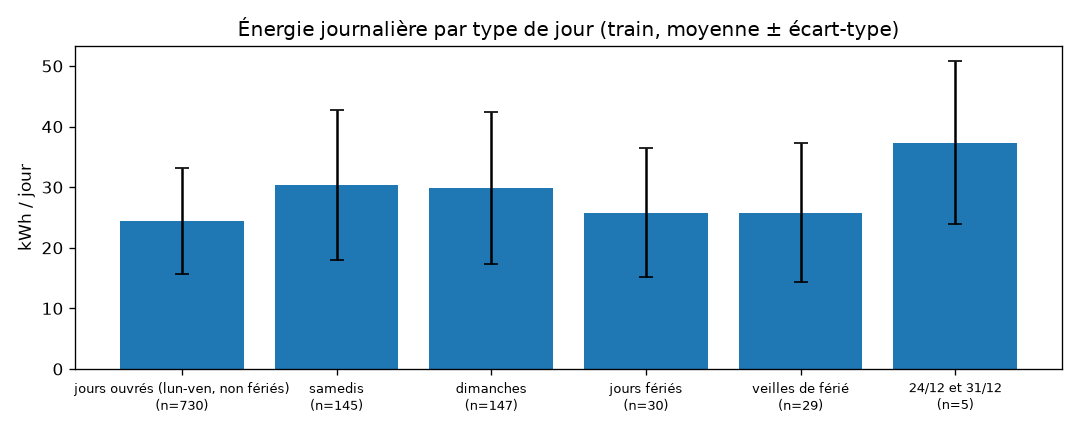

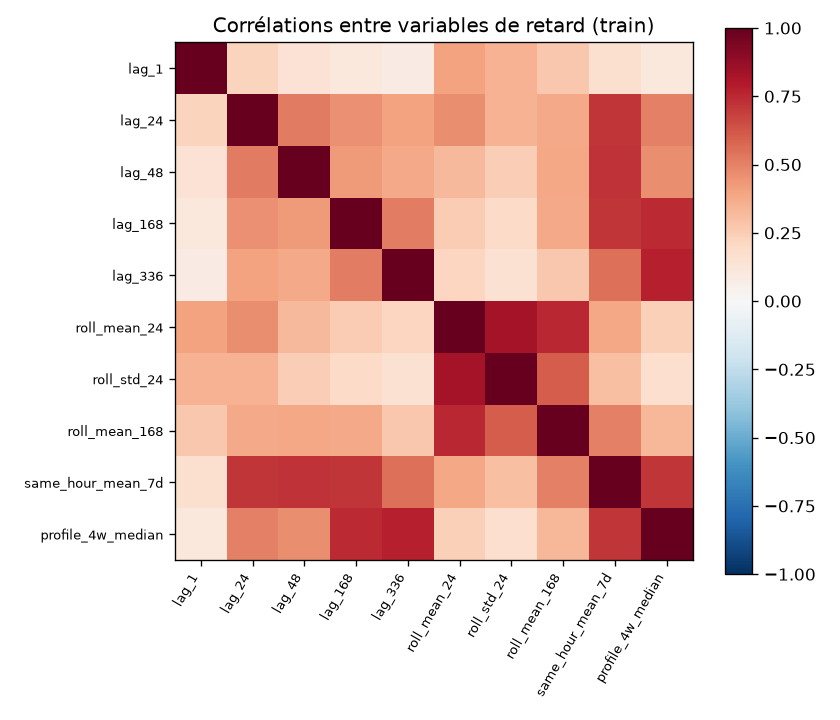

In [4]:
f = load('04_features_results.json'); display(pd.Series(f['spearman_with_y']).to_frame('Spearman avec y'))
display(pd.DataFrame(f['daily_energy_by_day_type']).T)
fig('04_lag1_by_horizon.png'); fig('04_day_types.png'); fig('04_lag_correlations.png')